# E2 Uncertainty Management

## Introduction

We study in this session the basics of uncertainty management and error propagation. En the [E1 notebook](E1_measurement_of_magnitudes.ipynb) 
we went over the basics of measurement of main magnitudes
on fluid flow from a fan. However, **every measurement is subject to an uncertainty**. When computing a global performance parameter (flow rate $Q$, 
pressure head $Y$ or efficiency $\eta$) this uncertainty propagates through the governing equations. It is important to consider this uncertainty in the 
final results in order to assess their reliability.


## Learning Objectives

- **Learn** the basics about measurement uncertainty according to the ISO 5168 standard and the Guide to the expression of uncertainty in measurement (GUM)
- **Identify** and quantify Type B uncertainties (sensor tolerance) for individual parameters using instrument specifications and ISO 5801 standard
- **Master** the use of the Python `uncertainties` package to automatically propagate measurement uncertainties
- **Estimate** uncertainty of final results of fan performance: flow rate, head, power, efficiency and dimensionless parameters

## Previous tasks (about 2 hours)

From [UNE-EN ISO 5801:2019](https://plataforma-aenormas-aenor-com.recursos.biblioteca.upc.edu/standard/UNE/N0061895) 
- Read Section 17 *Uncertainty analysis* (note that there is a recent modification of the standard in [UNE-EN ISO 5801:2019/A1:2025](https://plataforma-aenormas-aenor-com.recursos.biblioteca.upc.edu/standard/UNE/N0075114))

From [UNE-ISO 5168:2006](https://plataforma-aenormas-aenor-com.recursos.biblioteca.upc.edu/standard/UNE/N0036700)
- Read sections
  - 3 *Terms and definitions* Pay attention to the standardized vocabulary
  - 5 *General principles* 
  - 7 *Sources of uncertainty*
  - 8 *Sensitivity coefficients*
  - 9 *Combinations of uncertainties*
  - 10 *Expressions of results*

Section 4 of the ISO 5168 will be used as a reference for symbols.

## Some simple questions

## Tasks

Let's recover the example task for a centrifugal fan, studied in the [E1 Notebook](./E1_measurement_of_magnitudes.ipynb). These are the measured data:

In [1]:
import pandas as pd
import numpy as np

pd.set_option('display.float_format', '{:.4g}'.format) # To limit to 4 the number of significant digits in the output

P_e = np.array([1200, 1480, 1840, 2240, 2640, 3000, 3400, 3760]) # Power in watts
T = np.array([27.4, 25.7, 24.6, 24.0, 23.7, 23.6, 23.2, 22.5]) # Temperature in degrees Celsius
p = np.array([2.92, 3.06, 3.13, 3.13, 3.08, 2.92, 2.60, 2.23]) # Pressure in kPa, measured at the outlet of the system
p1 = np.array([2.92, 3.04, 3.09, 3.06, 2.96, 2.76, 2.38, 1.95]) # Pressure in kPa, measured at the inlet of the nozzle flow meter
Delta_p = np.array([0.0, 0.07, 0.27, 0.60, 1.05, 1.60, 2.38, 3.25]) # Pressure drop in kPa in nozzle flow meter (p2 - p1)
exp_data = pd.DataFrame({
    'P_e (W)': P_e,
    'T (°C)': T,
    'p (kPa)': p,
    'p1 (kPa)': p1,
    'Delta_p (kPa)': Delta_p
})
exp_data

,P_e (W),T (°C),p (kPa),p1 (kPa),Delta_p (kPa)
0,1200,27.4,2.92,2.92,0
1,1480,25.7,3.06,3.04,0.07
2,1840,24.6,3.13,3.09,0.27
3,2240,24,3.13,3.06,0.6
4,2640,23.7,3.08,2.96,1.05
5,3000,23.6,2.92,2.76,1.6
6,3400,23.2,2.6,2.38,2.38
7,3760,22.5,2.23,1.95,3.25


We are going to use the great python package [`uncertainties`](https://github.com/lmfit/uncertainties) that allows to make 
mathematical operations with quantities and its uncertainties, propagating the error. Let's we recompute the data frame for the 
acquired experimental data and its uncertainties, taken from the technical documentation of the measurement devices. 

This is a simple example:

```python
from uncertainties import ufloat, unumpy

a = ufloat(10.1, 0.1) # Example of a value with uncertainty
print(f"a = {a}")
b = ufloat(5.0, 0.2)  # Another value with uncertainty
print(f"b = {b}")
print(f"a + b = {c}") 
d = a * b
print(f"a * b = {d}") 
e = a / b
print(f"a / b = {e}") 
f = a*unumpy.log(b)
print(f"a * ln(b) = {f}") 
```
Result:

```
a = 10.10+/-0.10
b = 5.00+/-0.20
a + b = 15.10+/-0.22
a * b = 50.5+/-2.1
a / b = 2.02+/-0.08
a * ln(b) = 16.3+/-0.4
```

In [3]:
%pip install uncertainties
import uncertainties.unumpy as unp
from uncertainties import ufloat

# We define the errors in the measurements

w_p = 0.01 # kPa, error in pressure measurements
w_T = 0.4 # °C, error in temperature measurements
w_P_e = 10 # W, error in power measurements

# We create arrays of ufloat objects for each variable, combining the nominal values and their uncertainties
P_e_u = unp.uarray(P_e, w_P_e)
T_u = unp.uarray(T, w_T)
p_u = unp.uarray(p, w_p)
p1_u = unp.uarray(p1, w_p)
Delta_p_u = unp.uarray(Delta_p, w_p)
exp_data = pd.DataFrame({
    'P_e (W)': P_e_u,
    'T (°C)': T_u,
    'p (kPa)': p_u,
    'p1 (kPa)': p1_u,
    'Delta_p (kPa)': Delta_p_u
})
exp_data


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


,P_e (W),T (°C),p (kPa),p1 (kPa),Delta_p (kPa)
0,1200+/-10,27.4+/-0.4,2.920+/-0.010,2.920+/-0.010,0.000+/-0.010
1,1480+/-10,25.7+/-0.4,3.060+/-0.010,3.040+/-0.010,0.070+/-0.010
2,1840+/-10,24.6+/-0.4,3.130+/-0.010,3.090+/-0.010,0.270+/-0.010
3,2240+/-10,24.0+/-0.4,3.130+/-0.010,3.060+/-0.010,0.600+/-0.010
4,2640+/-10,23.7+/-0.4,3.080+/-0.010,2.960+/-0.010,1.050+/-0.010
5,3000+/-10,23.6+/-0.4,2.920+/-0.010,2.760+/-0.010,1.600+/-0.010
6,3400+/-10,23.2+/-0.4,2.600+/-0.010,2.380+/-0.010,2.380+/-0.010
7,3760+/-10,22.5+/-0.4,2.230+/-0.010,1.950+/-0.010,3.250+/-0.010


1. Compute rotational velocity and torque exactly as in the [E1 notebook](./E1_measurement_of_magnitudes.ipynb). The error will propagate to the new magnitudes

In [4]:
N2 = 2630
N1 = 2750
Pe_2_N = 3620
Pe_1_N = 400
exp_data['N (rpm)'] = (N2-N1) * (exp_data['P_e (W)'] - Pe_1_N) / (Pe_2_N - Pe_1_N) + N1
M2 = 12
M1 = 0
Pe_2_M = 4225
Pe_1_M = 165
exp_data['M (N m)'] = (M2-M1) * (exp_data['P_e (W)'] - Pe_1_M) / (Pe_2_M - Pe_1_M) + M1
exp_data

,P_e (W),T (°C),p (kPa),p1 (kPa),Delta_p (kPa),N (rpm),M (N m)
0,1200+/-10,27.4+/-0.4,2.920+/-0.010,2.920+/-0.010,0.000+/-0.010,2720.2+/-0.4,3.059+/-0.030
1,1480+/-10,25.7+/-0.4,3.060+/-0.010,3.040+/-0.010,0.070+/-0.010,2709.8+/-0.4,3.887+/-0.030
2,1840+/-10,24.6+/-0.4,3.130+/-0.010,3.090+/-0.010,0.270+/-0.010,2696.3+/-0.4,4.951+/-0.030
3,2240+/-10,24.0+/-0.4,3.130+/-0.010,3.060+/-0.010,0.600+/-0.010,2681.4+/-0.4,6.133+/-0.030
4,2640+/-10,23.7+/-0.4,3.080+/-0.010,2.960+/-0.010,1.050+/-0.010,2666.5+/-0.4,7.315+/-0.030
5,3000+/-10,23.6+/-0.4,2.920+/-0.010,2.760+/-0.010,1.600+/-0.010,2653.1+/-0.4,8.379+/-0.030
6,3400+/-10,23.2+/-0.4,2.600+/-0.010,2.380+/-0.010,2.380+/-0.010,2638.2+/-0.4,9.562+/-0.030
7,3760+/-10,22.5+/-0.4,2.230+/-0.010,1.950+/-0.010,3.250+/-0.010,2624.8+/-0.4,10.626+/-0.030


2. Repeat the same as in E1 notebook. Remember that ambient magnitudes (pressure and temperature) are also subject to uncertainty.

In [5]:
# Gas constant and ambient conditions (in SI base units: Pa, K, kg/m^3)
R = 287.05          # J/(kg·K)
P_a = 100.4 * 1e3   # Ambient pressure in Pa (100.4 kPa)
T_a = 21.0 + 273.15 # Ambient temperature in K (21.0 °C)
rho_a = P_a / (R * T_a) # Ambient air density in kg/m^3

# Compute absolute pressure (Pa) and absolute temperature (K) at nozzle inlet (point 1)
p1_abs = P_a + exp_data['p1 (kPa)'] * 1e3
T_abs = exp_data['T (°C)'] + 273.15

# Add density column to the DataFrame
exp_data['rho_1 (kg/m^3)'] = p1_abs / (R * T_abs)

print(f"Ambient density (rho_a): {rho_a:.4g} kg/m^3")
exp_data

Ambient density (rho_a): 1.189 kg/m^3


,P_e (W),T (°C),p (kPa),p1 (kPa),Delta_p (kPa),N (rpm),M (N m),rho_1 (kg/m^3)
0,1200+/-10,27.4+/-0.4,2.920+/-0.010,2.920+/-0.010,0.000+/-0.010,2720.2+/-0.4,3.059+/-0.030,1.1976+/-0.0016
1,1480+/-10,25.7+/-0.4,3.060+/-0.010,3.040+/-0.010,0.070+/-0.010,2709.8+/-0.4,3.887+/-0.030,1.2058+/-0.0016
2,1840+/-10,24.6+/-0.4,3.130+/-0.010,3.090+/-0.010,0.270+/-0.010,2696.3+/-0.4,4.951+/-0.030,1.2108+/-0.0016
3,2240+/-10,24.0+/-0.4,3.130+/-0.010,3.060+/-0.010,0.600+/-0.010,2681.4+/-0.4,6.133+/-0.030,1.2129+/-0.0016
4,2640+/-10,23.7+/-0.4,3.080+/-0.010,2.960+/-0.010,1.050+/-0.010,2666.5+/-0.4,7.315+/-0.030,1.2130+/-0.0016
5,3000+/-10,23.6+/-0.4,2.920+/-0.010,2.760+/-0.010,1.600+/-0.010,2653.1+/-0.4,8.379+/-0.030,1.2111+/-0.0016
6,3400+/-10,23.2+/-0.4,2.600+/-0.010,2.380+/-0.010,2.380+/-0.010,2638.2+/-0.4,9.562+/-0.030,1.2082+/-0.0016
7,3760+/-10,22.5+/-0.4,2.230+/-0.010,1.950+/-0.010,3.250+/-0.010,2624.8+/-0.4,10.626+/-0.030,1.2060+/-0.0016


3. Compute viscosity for the point 1 in the test bench.

In [6]:
# Dynamic viscosity at point 1 in Pa·s (T is directly in °C)
exp_data['mu_1 (Pa s)'] = (17.1 + 0.048 * exp_data['T (°C)']) * 1e-6

exp_data

,P_e (W),T (°C),p (kPa),p1 (kPa),Delta_p (kPa),N (rpm),M (N m),rho_1 (kg/m^3),mu_1 (Pa s)
0,1200+/-10,27.4+/-0.4,2.920+/-0.010,2.920+/-0.010,0.000+/-0.010,2720.2+/-0.4,3.059+/-0.030,1.1976+/-0.0016,(1.8415+/-0.0019)e-05
1,1480+/-10,25.7+/-0.4,3.060+/-0.010,3.040+/-0.010,0.070+/-0.010,2709.8+/-0.4,3.887+/-0.030,1.2058+/-0.0016,(1.8334+/-0.0019)e-05
2,1840+/-10,24.6+/-0.4,3.130+/-0.010,3.090+/-0.010,0.270+/-0.010,2696.3+/-0.4,4.951+/-0.030,1.2108+/-0.0016,(1.8281+/-0.0019)e-05
3,2240+/-10,24.0+/-0.4,3.130+/-0.010,3.060+/-0.010,0.600+/-0.010,2681.4+/-0.4,6.133+/-0.030,1.2129+/-0.0016,(1.8252+/-0.0019)e-05
4,2640+/-10,23.7+/-0.4,3.080+/-0.010,2.960+/-0.010,1.050+/-0.010,2666.5+/-0.4,7.315+/-0.030,1.2130+/-0.0016,(1.8238+/-0.0019)e-05
5,3000+/-10,23.6+/-0.4,2.920+/-0.010,2.760+/-0.010,1.600+/-0.010,2653.1+/-0.4,8.379+/-0.030,1.2111+/-0.0016,(1.8233+/-0.0019)e-05
6,3400+/-10,23.2+/-0.4,2.600+/-0.010,2.380+/-0.010,2.380+/-0.010,2638.2+/-0.4,9.562+/-0.030,1.2082+/-0.0016,(1.8214+/-0.0019)e-05
7,3760+/-10,22.5+/-0.4,2.230+/-0.010,1.950+/-0.010,3.250+/-0.010,2624.8+/-0.4,10.626+/-0.030,1.2060+/-0.0016,(1.8180+/-0.0019)e-05


4. The computation of the flow rate is tricky. It cannot be done directly with uncertainties numerical objects, since the functions in fluid.flow_meter module accept only numbers.  

In [10]:
from fluids.flow_meter import differential_pressure_meter_solver

# Nozzle geometry and gas properties
D = 0.1829   # Duct diameter in m
D2 = 0.1140  # Nozzle throat diameter in m
k = 1.4      # Adiabatic index for air

m_dot_list = []

for _, row in exp_data.iterrows():
    if row['Delta_p (kPa)'].nominal_value == 0:
        m_dot_list.append(0.0)
    else:
        P1_abs = (P_a + row['p1 (kPa)'] * 1e3).nominal_value
        P2_abs = P1_abs - (row['Delta_p (kPa)'] * 1e3).nominal_value
        
        m_dot = differential_pressure_meter_solver(
            D=D,
            D2=D2,
            rho=row['rho_1 (kg/m^3)'].nominal_value,
            mu=row['mu_1 (Pa s)'].nominal_value,
            P1=P1_abs,
            P2=P2_abs,
            k=k,
            meter_type='ISA 1932 nozzle'
        )
        m_dot_list.append(m_dot)

exp_data['m_dot (kg/s)'] = m_dot_list
exp_data

,P_e (W),T (°C),p (kPa),p1 (kPa),Delta_p (kPa),N (rpm),M (N m),rho_1 (kg/m^3),mu_1 (Pa s),m_dot (kg/s)
0,1200+/-10,27.4+/-0.4,2.920+/-0.010,2.920+/-0.010,0.000+/-0.010,2720.2+/-0.4,3.059+/-0.030,1.1976+/-0.0016,(1.8415+/-0.0019)e-05,0
1,1480+/-10,25.7+/-0.4,3.060+/-0.010,3.040+/-0.010,0.070+/-0.010,2709.8+/-0.4,3.887+/-0.030,1.2058+/-0.0016,(1.8334+/-0.0019)e-05,0.1368
2,1840+/-10,24.6+/-0.4,3.130+/-0.010,3.090+/-0.010,0.270+/-0.010,2696.3+/-0.4,4.951+/-0.030,1.2108+/-0.0016,(1.8281+/-0.0019)e-05,0.2699
3,2240+/-10,24.0+/-0.4,3.130+/-0.010,3.060+/-0.010,0.600+/-0.010,2681.4+/-0.4,6.133+/-0.030,1.2129+/-0.0016,(1.8252+/-0.0019)e-05,0.4023
4,2640+/-10,23.7+/-0.4,3.080+/-0.010,2.960+/-0.010,1.050+/-0.010,2666.5+/-0.4,7.315+/-0.030,1.2130+/-0.0016,(1.8238+/-0.0019)e-05,0.5309
5,3000+/-10,23.6+/-0.4,2.920+/-0.010,2.760+/-0.010,1.600+/-0.010,2653.1+/-0.4,8.379+/-0.030,1.2111+/-0.0016,(1.8233+/-0.0019)e-05,0.6527
6,3400+/-10,23.2+/-0.4,2.600+/-0.010,2.380+/-0.010,2.380+/-0.010,2638.2+/-0.4,9.562+/-0.030,1.2082+/-0.0016,(1.8214+/-0.0019)e-05,0.7912
7,3760+/-10,22.5+/-0.4,2.230+/-0.010,1.950+/-0.010,3.250+/-0.010,2624.8+/-0.4,10.626+/-0.030,1.2060+/-0.0016,(1.8180+/-0.0019)e-05,0.9185


5. Compute density of air at the outlet of the fan and use mass flow rate to calculate volumetric flow rate in the fan. We need it to get velocity
   and total pressure.

In [11]:
# Absolute pressure (Pa) and absolute temperature (K) at the fan outlet
p_abs = P_a + exp_data['p (kPa)'] * 1e3
T_abs = exp_data['T (°C)'] + 273.15

# Air density at the fan outlet (kg/m^3)
exp_data['rho (kg/m^3)'] = p_abs / (R * T_abs)

# Volumetric flow rate at the fan outlet (m^3/s)
exp_data['Q (m^3/s)'] = exp_data['m_dot (kg/s)'] / exp_data['rho (kg/m^3)']

exp_data[['P_e (W)', 'p (kPa)', 'm_dot (kg/s)', 'rho (kg/m^3)', 'Q (m^3/s)']]

,P_e (W),p (kPa),m_dot (kg/s),rho (kg/m^3),Q (m^3/s)
0,1200+/-10,2.920+/-0.010,0,1.1976+/-0.0016,0.0+/-0
1,1480+/-10,3.060+/-0.010,0.1368,1.2060+/-0.0016,0.11343+/-0.00015
2,1840+/-10,3.130+/-0.010,0.2699,1.2113+/-0.0016,0.22281+/-0.00030
3,2240+/-10,3.130+/-0.010,0.4023,1.2138+/-0.0016,0.3314+/-0.0004
4,2640+/-10,3.080+/-0.010,0.5309,1.2144+/-0.0016,0.4372+/-0.0006
5,3000+/-10,2.920+/-0.010,0.6527,1.2129+/-0.0016,0.5381+/-0.0007
6,3400+/-10,2.600+/-0.010,0.7912,1.2108+/-0.0016,0.6535+/-0.0009
7,3760+/-10,2.230+/-0.010,0.9185,1.2093+/-0.0016,0.7596+/-0.0010


6. Compute average velocity of air at fan outlet with flow rate and duct section

In [12]:
# Duct cross-sectional area in m^2 (D = 0.1829 m)
A_duct = (np.pi / 4) * D**2

# Average air velocity at the fan outlet in m/s
exp_data['v (m/s)'] = exp_data['Q (m^3/s)'] / A_duct

exp_data[['Q (m^3/s)', 'v (m/s)']]

,Q (m^3/s),v (m/s)
0,0.0+/-0,0.0+/-0
1,0.11343+/-0.00015,4.317+/-0.006
2,0.22281+/-0.00030,8.480+/-0.011
3,0.3314+/-0.0004,12.615+/-0.017
4,0.4372+/-0.0006,16.640+/-0.022
5,0.5381+/-0.0007,20.482+/-0.028
6,0.6535+/-0.0009,24.872+/-0.034
7,0.7596+/-0.0010,28.91+/-0.04


7. Estimate mechanical energy rise $Y = \frac{\Delta p_0}{\rho}$ in $\text{J/kg}$, taking $\rho$ as the average between the inlet and outlet densities.

In [13]:
# Total pressure rise across the fan in Pa (inlet is ambient stagnation: p_0,in = P_a)
exp_data['Delta_p0 (Pa)'] = exp_data['p (kPa)'] * 1e3 + 0.5 * exp_data['rho (kg/m^3)'] * exp_data['v (m/s)']**2

# Average density between fan inlet (ambient) and fan outlet
rho_avg = 0.5 * (rho_a + exp_data['rho (kg/m^3)'])

# Specific mechanical energy rise in J/kg
exp_data['Y (J/kg)'] = exp_data['Delta_p0 (Pa)'] / rho_avg

exp_data[['p (kPa)', 'v (m/s)', 'Delta_p0 (Pa)', 'Y (J/kg)']]

,p (kPa),v (m/s),Delta_p0 (Pa),Y (J/kg)
0,2.920+/-0.010,0.0+/-0,2920+/-10,2447+/-8
1,3.060+/-0.010,4.317+/-0.006,3071+/-10,2565+/-8
2,3.130+/-0.010,8.480+/-0.011,3174+/-10,2644+/-8
3,3.130+/-0.010,12.615+/-0.017,3227+/-10,2686+/-8
4,3.080+/-0.010,16.640+/-0.022,3248+/-10,2703+/-8
5,2.920+/-0.010,20.482+/-0.028,3174+/-10,2643+/-8
6,2.600+/-0.010,24.872+/-0.034,2975+/-10,2479+/-8
7,2.230+/-0.010,28.91+/-0.04,2735+/-10,2281+/-8


8. Estimate mechanical efficiency as 
$$
\eta = \frac{\Delta p_0 Q}{\omega M}
$$

In [14]:
# Linear calibration for motor torque M (N·m)
slope_M = (12.0 - 0.0) / (4225.0 - 165.0)
exp_data['M (N m)'] = slope_M * (exp_data['P_e (W)'] - 165.0)

# Linear calibration for rotational speed N (rpm) and angular velocity omega (rad/s)
slope_N = (2630.0 - 2750.0) / (3620.0 - 400.0)
exp_data['N (rpm)'] = 2750.0 + slope_N * (exp_data['P_e (W)'] - 400.0)
exp_data['omega (rad/s)'] = exp_data['N (rpm)'] * (2 * np.pi / 60.0)

# Mechanical shaft power P (W) and mechanical efficiency eta
exp_data['P (W)'] = exp_data['omega (rad/s)'] * exp_data['M (N m)']
exp_data['eta'] = (exp_data['Delta_p0 (Pa)'] * exp_data['Q (m^3/s)']) / exp_data['P (W)']

exp_data[['P_e (W)', 'M (N m)', 'N (rpm)', 'P (W)', 'eta']]

,P_e (W),M (N m),N (rpm),P (W),eta
0,1200+/-10,3.059+/-0.030,2720.2+/-0.4,871+/-8,0.0+/-0
1,1480+/-10,3.887+/-0.030,2709.8+/-0.4,1103+/-8,0.3159+/-0.0026
2,1840+/-10,4.951+/-0.030,2696.3+/-0.4,1398+/-8,0.5058+/-0.0034
3,2240+/-10,6.133+/-0.030,2681.4+/-0.4,1722+/-8,0.621+/-0.004
4,2640+/-10,7.315+/-0.030,2666.5+/-0.4,2043+/-8,0.695+/-0.004
5,3000+/-10,8.379+/-0.030,2653.1+/-0.4,2328+/-8,0.7338+/-0.0035
6,3400+/-10,9.562+/-0.030,2638.2+/-0.4,2642+/-8,0.7358+/-0.0034
7,3760+/-10,10.626+/-0.030,2624.8+/-0.4,2921+/-8,0.7114+/-0.0033


9. Again, scale flow rate, mechanical energy and consumed mechanical power to the idling rotational velocity $N_0 = 2750 \,\text{rpm}$, considering similitude relationships 

In [19]:
import matplotlib.pyplot as plt
from uncertainties import unumpy

# 1. Scale Q, Y, and P to the reference idling speed N0 = 2750 rpm
N0 = 2750.0
speed_ratio = N0 / exp_data['N (rpm)']

exp_data['Q_0 (m^3/s)'] = exp_data['Q (m^3/s)'] * speed_ratio
exp_data['Y_0 (J/kg)']  = exp_data['Y (J/kg)'] * (speed_ratio ** 2)
exp_data['P_0 (W)']     = exp_data['P (W)'] * (speed_ratio ** 3)

# 2. Specific speed Omega_s at the Best Efficiency Point (BEP)
bep = exp_data.loc[exp_data['eta'].idxmax()]
Omega_s = (bep['omega (rad/s)'] * unumpy.sqrt(bep['Q (m^3/s)'])) / (bep['Y (J/kg)'] ** 0.75)

print(f"Best Efficiency Point (BEP): eta_max = {bep['eta']} at Q_0 = {bep['Q_0 (m^3/s)']} m^3/s")
print(f"Dimensionless Specific Speed at BEP: Omega_s = {Omega_s}")

Best Efficiency Point (BEP): eta_max = 0.7358+/-0.0034 at Q_0 = 0.6812+/-0.0009 m^3/s
Dimensionless Specific Speed at BEP: Omega_s = 0.6357+/-0.0016


10.  Plot performance curves $Y(Q)$, $P/Q)$ and $\eta(Q)$ with the error bars and uncertainty bands. Draw conclusions.

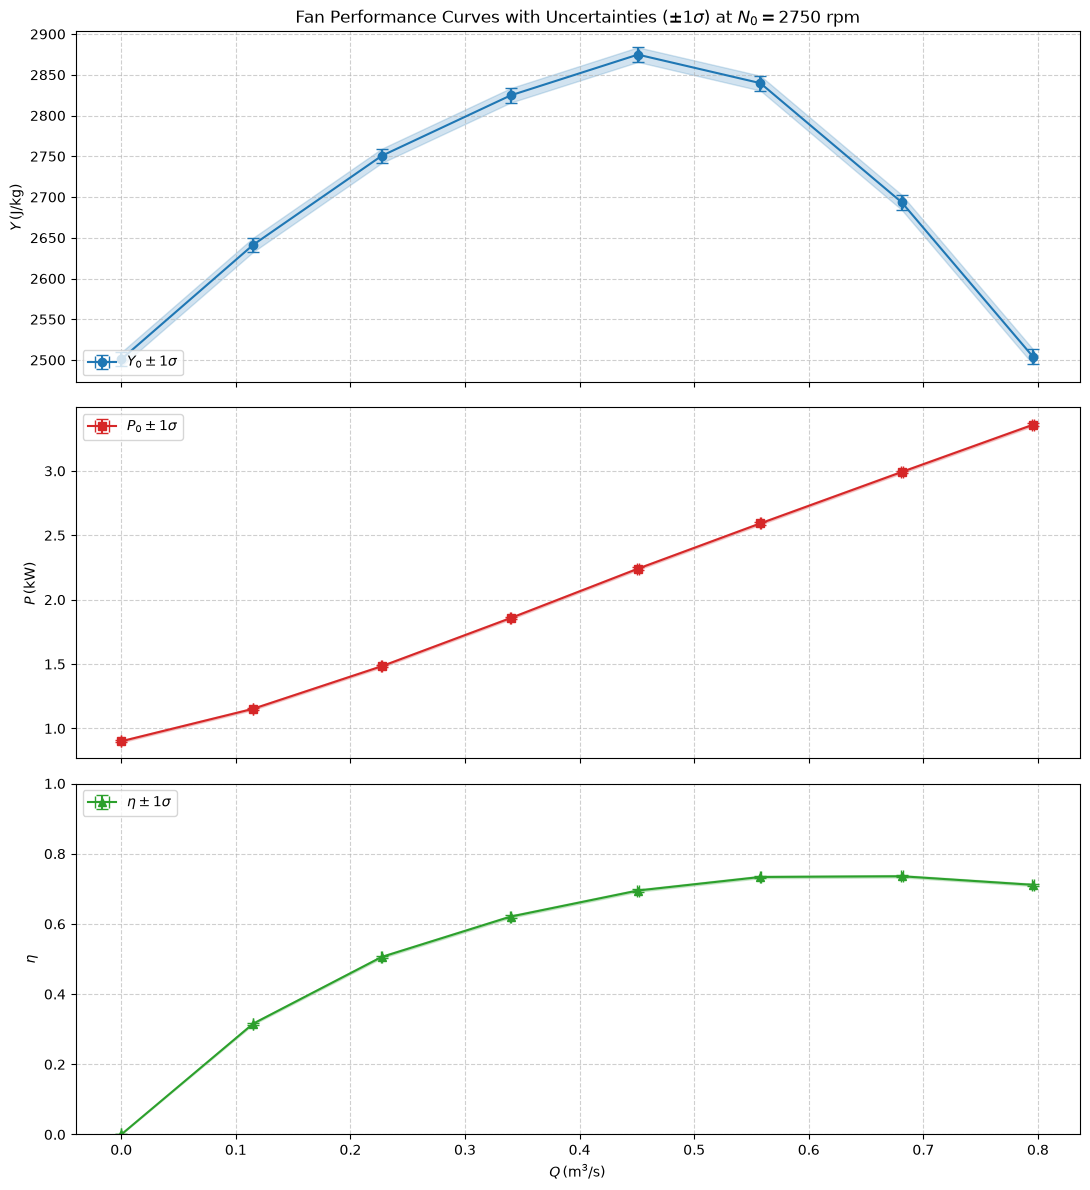

In [21]:
import matplotlib.pyplot as plt
from uncertainties import unumpy

# Ensure P_N (kW) is defined with uncertainties propagated
exp_data['P_N (kW)'] = exp_data['P_0 (W)'] / 1000.0

# Extract nominal values and standard deviations (1-sigma uncertainties)
Q_nom = unumpy.nominal_values(exp_data['Q_0 (m^3/s)'])
Q_err = unumpy.std_devs(exp_data['Q_0 (m^3/s)'])

Y_nom = unumpy.nominal_values(exp_data['Y_0 (J/kg)'])
Y_err = unumpy.std_devs(exp_data['Y_0 (J/kg)'])

P_nom = unumpy.nominal_values(exp_data['P_N (kW)'])
P_err = unumpy.std_devs(exp_data['P_N (kW)'])

eta_nom = unumpy.nominal_values(exp_data['eta'])
eta_err = unumpy.std_devs(exp_data['eta'])

# Create 3-panel performance plot
fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)

# --- 1. Specific Mechanical Energy Y(Q) ---
axes[0].errorbar(Q_nom, Y_nom, xerr=Q_err, yerr=Y_err, fmt='o-', color='tab:blue',
                 ecolor='tab:blue', elinewidth=1.5, capsize=4, label=r'$Y_0 \pm 1\sigma$')
axes[0].fill_between(Q_nom, Y_nom - Y_err, Y_nom + Y_err, color='tab:blue', alpha=0.2)
axes[0].set_title(r'Fan Performance Curves with Uncertainties ($\pm 1\sigma$) at $N_0 = 2750$ rpm')
axes[0].set_ylabel(r'$Y\,\mathrm{(J/kg)}$')
axes[0].legend(loc='lower left')

# --- 2. Consumed Shaft Power P(Q) ---
axes[1].errorbar(Q_nom, P_nom, xerr=Q_err, yerr=P_err, fmt='s-', color='tab:red',
                 ecolor='tab:red', elinewidth=1.5, capsize=4, label=r'$P_0 \pm 1\sigma$')
axes[1].fill_between(Q_nom, P_nom - P_err, P_nom + P_err, color='tab:red', alpha=0.2)
axes[1].set_ylabel(r'$P\,\mathrm{(kW)}$')
axes[1].legend(loc='upper left')

# --- 3. Mechanical Efficiency eta(Q) ---
axes[2].errorbar(Q_nom, eta_nom, xerr=Q_err, yerr=eta_err, fmt='^-', color='tab:green',
                 ecolor='tab:green', elinewidth=1.5, capsize=4, label=r'$\eta \pm 1\sigma$')
axes[2].fill_between(Q_nom, eta_nom - eta_err, eta_nom + eta_err, color='tab:green', alpha=0.2)
axes[2].set_ylabel(r'$\eta$')
axes[2].set_xlabel(r'$Q\,\mathrm{(m}^3\mathrm{/s)}$')
axes[2].set_ylim(0, 1)
axes[2].legend(loc='upper left')

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

11.  Compute additional columns with relative uncertainty for $Q_N$, $Y_N$, $P_N$ and $\eta$. Plot and check if it fulfills the ISO 5801 requirements 

<>:55: SyntaxWarning: invalid escape sequence '\e'
<>:55: SyntaxWarning: invalid escape sequence '\e'
C:\Users\Guill\AppData\Local\Temp\ipykernel_24192\356925688.py:55: SyntaxWarning: invalid escape sequence '\e'
  (axes[1, 1], 'U_rel_eta (%)', r'$U_{95\%}(\eta)$ (%)', iso_limits['eta'], 'tab:green',  'Efficiency ($\eta$)')


95% Expanded Relative Uncertainties (k = 2) vs ISO 5801 Limits:
         Q_N (m^3/s)  U_rel_Q (%)  U_rel_Y (%)  U_rel_P (%)  U_rel_eta (%)
0            0.0+/-0          NaN         0.69         1.99            NaN
1  0.11512+/-0.00016         0.27         0.66         1.58           1.64
2  0.22724+/-0.00031         0.27         0.64         1.25           1.34
3    0.3399+/-0.0005         0.27         0.63         1.02           1.15
4    0.4509+/-0.0006         0.27         0.63         0.86           1.02
5    0.5578+/-0.0008         0.27         0.64         0.76           0.96
6    0.6812+/-0.0009         0.27         0.68         0.67           0.93
7    0.7958+/-0.0011         0.27         0.74         0.61           0.94

--- ISO 5801 Compliance Check at BEP (Index 6) ---
Q_N : 0.27%  (Limit: <= 2.0%)  -> PASS
Y_N : 0.68%  (Limit: <= 1.4%)  -> PASS
P_N : 0.67%  (Limit: <= 2.5%)  -> PASS
eta : 0.93%  (Limit: <= 3.2%)  -> PASS


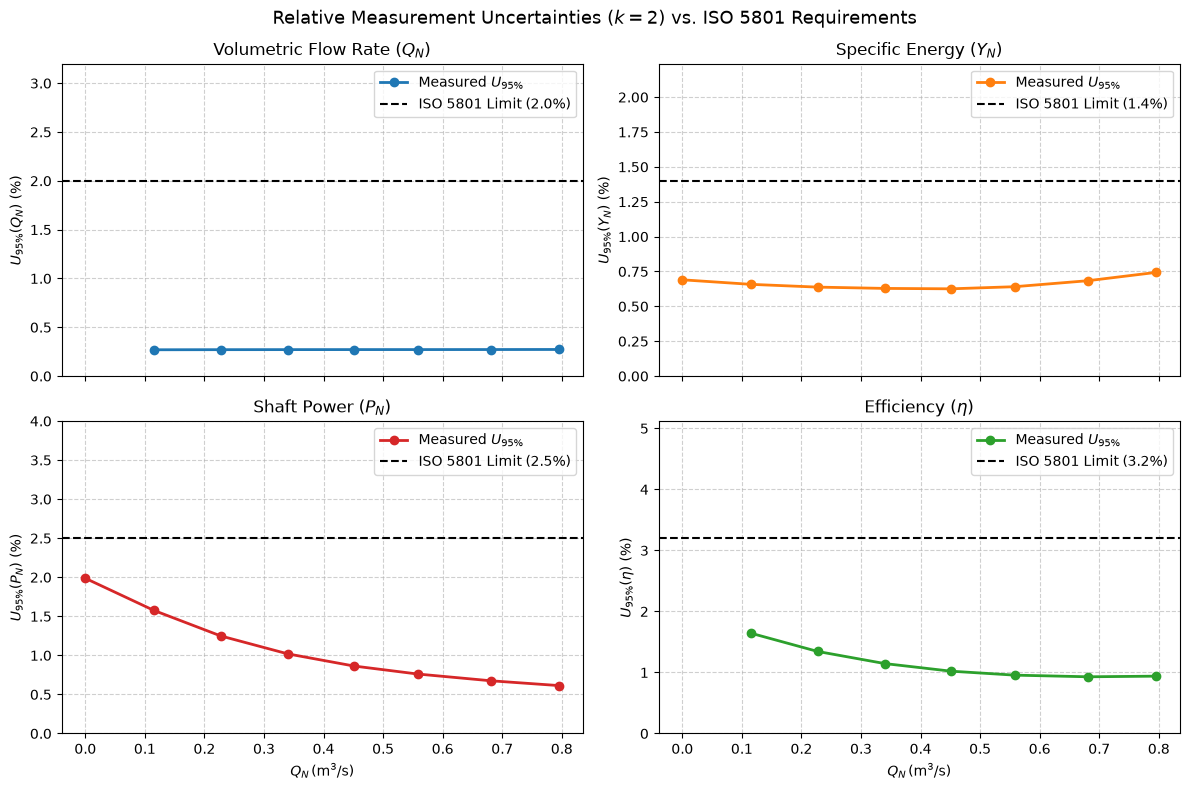

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from uncertainties import unumpy

# Ensure Q_N, Y_N, and P_N columns exist
exp_data['Q_N (m^3/s)'] = exp_data['Q_0 (m^3/s)']
exp_data['Y_N (J/kg)']  = exp_data['Y_0 (J/kg)']
exp_data['P_N (kW)']    = exp_data['P_0 (W)'] / 1000.0

# Helper function to compute expanded relative uncertainty U_95% = 2 * (std / nominal) * 100
def rel_uncertainty_95(series):
    nom = unumpy.nominal_values(series)
    std = unumpy.std_devs(series)
    with np.errstate(divide='ignore', invalid='ignore'):
        u_rel_95 = np.where(nom != 0, 2.0 * (std / np.abs(nom)) * 100.0, np.nan)
    return u_rel_95

# Compute 95% expanded relative uncertainty (%) columns
exp_data['U_rel_Q (%)']   = rel_uncertainty_95(exp_data['Q_N (m^3/s)'])
exp_data['U_rel_Y (%)']   = rel_uncertainty_95(exp_data['Y_N (J/kg)'])
exp_data['U_rel_P (%)']   = rel_uncertainty_95(exp_data['P_N (kW)'])
exp_data['U_rel_eta (%)'] = rel_uncertainty_95(exp_data['eta'])

# ISO 5801 maximum permissible 95% expanded uncertainties (%)
iso_limits = {
    'Q_N': 2.0,
    'Y_N': 1.4,
    'P_N': 2.5,
    'eta': 3.2
}

# Print summary table of relative uncertainties (%)
cols_to_show = ['Q_N (m^3/s)', 'U_rel_Q (%)', 'U_rel_Y (%)', 'U_rel_P (%)', 'U_rel_eta (%)']
print("95% Expanded Relative Uncertainties (k = 2) vs ISO 5801 Limits:")
print(exp_data[cols_to_show].to_string(float_format=lambda x: f"{x:.2f}"))

# Check compliance at the Best Efficiency Point (BEP)
bep_idx = unumpy.nominal_values(exp_data['eta']).argmax()
bep_row = exp_data.iloc[bep_idx]
print(f"\n--- ISO 5801 Compliance Check at BEP (Index {bep_idx}) ---")
print(f"Q_N : {bep_row['U_rel_Q (%)']:.2f}%  (Limit: <= {iso_limits['Q_N']}%)  -> {'PASS' if bep_row['U_rel_Q (%)'] <= iso_limits['Q_N'] else 'FAIL'}")
print(f"Y_N : {bep_row['U_rel_Y (%)']:.2f}%  (Limit: <= {iso_limits['Y_N']}%)  -> {'PASS' if bep_row['U_rel_Y (%)'] <= iso_limits['Y_N'] else 'FAIL'}")
print(f"P_N : {bep_row['U_rel_P (%)']:.2f}%  (Limit: <= {iso_limits['P_N']}%)  -> {'PASS' if bep_row['U_rel_P (%)'] <= iso_limits['P_N'] else 'FAIL'}")
print(f"eta : {bep_row['U_rel_eta (%)']:.2f}%  (Limit: <= {iso_limits['eta']}%)  -> {'PASS' if bep_row['U_rel_eta (%)'] <= iso_limits['eta'] else 'FAIL'}")

# --- Plot Relative Uncertainties vs Q_N with ISO 5801 Threshold Lines ---
Q_nom = unumpy.nominal_values(exp_data['Q_N (m^3/s)'])

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)

plots = [
    (axes[0, 0], 'U_rel_Q (%)',   r'$U_{95\%}(Q_N)$ (%)',   iso_limits['Q_N'],   'tab:blue',   'Volumetric Flow Rate ($Q_N$)'),
    (axes[0, 1], 'U_rel_Y (%)',   r'$U_{95\%}(Y_N)$ (%)',   iso_limits['Y_N'],   'tab:orange', 'Specific Energy ($Y_N$)'),
    (axes[1, 0], 'U_rel_P (%)',   r'$U_{95\%}(P_N)$ (%)',   iso_limits['P_N'],   'tab:red',    'Shaft Power ($P_N$)'),
    (axes[1, 1], 'U_rel_eta (%)', r'$U_{95\%}(\eta)$ (%)', iso_limits['eta'], 'tab:green',  'Efficiency ($\eta$)')
]

for ax, col, ylabel, limit, color, title in plots:
    ax.plot(Q_nom, exp_data[col], 'o-', color=color, linewidth=2, label='Measured $U_{95\\%}$')
    ax.axhline(limit, color='black', linestyle='--', linewidth=1.5, label=f'ISO 5801 Limit ({limit}%)')
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(limit * 1.6, np.nanmax(exp_data[col][1:]) * 1.15))
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend()

axes[1, 0].set_xlabel(r'$Q_N\,\mathrm{(m^3/s)}$')
axes[1, 1].set_xlabel(r'$Q_N\,\mathrm{(m^3/s)}$')

plt.suptitle('Relative Measurement Uncertainties ($k=2$) vs. ISO 5801 Requirements', fontsize=13)
plt.tight_layout()
plt.show()

## Your project

With respect to your project:
- Look for the errors of measurements on the technical documentation of every device and make a list.
- Consider a particular operation point, conveniently close to the BEP, and make an estimation of the error that you will get for pressure, flow rate, power and efficiency.

In [26]:
import uncertainties
from uncertainties import ufloat, unumpy
import numpy as np

# Fan: Soler & Palau HCFB/4-630/H (D = 0.630 m, N = 1380 rpm, Q_max = 17230 m3/h = 4.786 m3/s, P_e = 1573 W)
# Let's define a realistic operating point near the BEP (~75-80% of free-delivery flow):
# Q_bep = 13500 m3/h = 3.75 m3/s
# Bellmouth inlet nozzle throat d = 0.45 m (A_throat = pi/4 * 0.45^2 = 0.15904 m2)
# Duct diameter D = 0.630 m (A_duct = pi/4 * 0.630^2 = 0.31172 m2)

R = 287.05
# Ambient conditions & instrument errors (k=1 standard uncertainties from rectangular/normal datasheet tolerances)
# 1. Barometer (ambient pressure P_a): typical digital barometer +/- 100 Pa (1 hPa) -> u = 100 / sqrt(3) or 50 Pa
P_a = ufloat(101325.0, 100.0 / np.sqrt(3))  # Pa

# 2. Temperature: TC Direct Type K General Purpose Probe (IEC 60584 Class 1: +/- 1.5 °C) + USB Logger (e.g. TC-08: +/- 0.5 °C)
# Combined rectangular/normal standard uncertainty: u_T = sqrt((1.5/sqrt(3))^2 + (0.5/sqrt(3))^2) = 0.91 °C
T_a_C = ufloat(22.0, np.sqrt((1.5/np.sqrt(3))**2 + (0.5/np.sqrt(3))**2))
T_C   = ufloat(22.6, np.sqrt((1.5/np.sqrt(3))**2 + (0.5/np.sqrt(3))**2))

T_a = T_a_C + 273.15
T   = T_C + 273.15

# 3. Differential pressure across Bellmouth Nozzle (Delta_p):
# WIKA A2G-50 (range 0..500 Pa, accuracy +/- 1.5% FS = +/- 7.5 Pa) OR Keller PD-41X / WIKA CPG1500 (range 0..1000 Pa / 2500 Pa, accuracy 0.1% FS = +/- 1.0 Pa to 2.5 Pa)
# Let's check with Keller PD-41X (0..1000 Pa, +/- 0.1% FS = +/- 1.0 Pa) or WIKA CPG1500 (0..25 mbar = 2500 Pa, 0.05% FS = +/- 1.25 Pa)
# At Q = 3.75 m3/s, v_throat = 3.75 / 0.15904 = 23.58 m/s -> Delta_p = 0.5 * 1.2 * 23.58^2 / 0.985^2 = 343.8 Pa
Delta_p = ufloat(344.0, 1.25 / np.sqrt(3))  # WIKA CPG1500 (0.05% FS of 2500 Pa = 1.25 Pa) or Keller PD-41X (0.1% FS of 1000 Pa = 1.0 Pa)

# 4. Static gauge pressure at fan outlet / chamber (p):
# At BEP, static pressure p ~ 160 Pa
# Using Keller PD-41X (0..300 Pa or 0..1000 Pa, +/- 0.1% FS = +/- 1.0 Pa) or WIKA A2G-50 (0..250 Pa, +/- 1.5% FS = +/- 3.75 Pa)
p = ufloat(160.0, 1.0 / np.sqrt(3))  # Pa

# 5. Bellmouth discharge coefficient C_d (ISO 5801 bellmouth inlet: C_d = 0.985 +/- 0.5% -> 0.005 * 0.985)
C_d = ufloat(0.985, (0.005 * 0.985) / np.sqrt(3))
d_throat = ufloat(0.450, 0.0005 / np.sqrt(3))  # +/- 0.5 mm machining tolerance
D_duct = 0.630

# 6. Calibrated motor / Electrical power & Speed:
# Electrical power P_e ~ 1420 W (Class 0.5 wattmeter: +/- 0.5% rdg = +/- 7.1 W; motor calibration fit uncertainty +/- 1.5% on torque/shaft power)
# Tachometer N = 1365 rpm (+/- 1 rpm -> u = 1 / sqrt(3))
P_shaft = ufloat(1180.0, (0.015 * 1180.0) / np.sqrt(3))  # W (calibrated motor shaft power uncertainty ~1.5% limit -> 0.87% 1-sigma)
N = ufloat(1365.0, 1.0 / np.sqrt(3))

# Calculations:
rho_a = P_a / (R * T_a)
rho_out = (P_a + p) / (R * T)
rho_avg = 0.5 * (rho_a + rho_out)

A_throat = (np.pi / 4) * d_throat**2
m_dot = C_d * A_throat * unumpy.sqrt(2 * rho_a * Delta_p)
Q = m_dot / rho_out

A_duct = (np.pi / 4) * D_duct**2
v = Q / A_duct
Delta_p0 = p + 0.5 * rho_out * v**2
Y = Delta_p0 / rho_avg
eta = (Delta_p0 * Q) / P_shaft

for name, val in [('rho_out (kg/m3)', rho_out), ('Q (m3/s)', Q), ('Delta_p0 (Pa)', Delta_p0), ('Y (J/kg)', Y), ('P_shaft (W)', P_shaft), ('eta (-)', eta)]:
    u_rel_1s = (val.std_dev / val.nominal_value) * 100
    u_rel_95 = 2 * u_rel_1s
    print(f"{name:15s}: {val.nominal_value:8.3f} +/- {val.std_dev:6.3f} (1s) | u_rel(1s) = {u_rel_1s:.2f}% | U_95%(k=2) = {u_rel_95:.2f}%")

rho_out (kg/m3):    1.195 +/-  0.004 (1s) | u_rel(1s) = 0.31% | U_95%(k=2) = 0.63%
Q (m3/s)       :    3.759 +/-  0.018 (1s) | u_rel(1s) = 0.48% | U_95%(k=2) = 0.96%
Delta_p0 (Pa)  :  246.919 +/-  0.901 (1s) | u_rel(1s) = 0.36% | U_95%(k=2) = 0.73%
Y (J/kg)       :  206.508 +/-  0.885 (1s) | u_rel(1s) = 0.43% | U_95%(k=2) = 0.86%
P_shaft (W)    : 1180.000 +/- 10.219 (1s) | u_rel(1s) = 0.87% | U_95%(k=2) = 1.73%
eta (-)        :    0.787 +/-  0.009 (1s) | u_rel(1s) = 1.17% | U_95%(k=2) = 2.34%


In [27]:
import numpy as np

# Monte Carlo / exact analytical propagation for BEP operating point of S&P HCFB/4-630/H
np.random.seed(42)
N_mc = 500_000

R = 287.05
D_duct = 0.630

# Inputs: nominal and standard uncertainty u (k=1, rectangular limits divided by sqrt(3))
P_a_nom, u_Pa = 101325.0, 100.0 / np.sqrt(3)
Ta_nom, u_T = 22.0, np.sqrt((1.5/np.sqrt(3))**2 + (0.5/np.sqrt(3))**2)
T_nom = 22.6

# Keller PD-41X (0..1000 Pa, 0.1% FS = +/- 1.0 Pa) or WIKA CPG1500 (0..2500 Pa, 0.05% FS = +/- 1.25 Pa)
dp_nom, u_dp = 344.0, 1.0 / np.sqrt(3)
p_nom, u_p = 160.0, 1.0 / np.sqrt(3)

Cd_nom, u_Cd = 0.985, (0.005 * 0.985) / np.sqrt(3)
d_nom, u_d = 0.450, 0.0005 / np.sqrt(3)
Pshaft_nom, u_Pshaft = 1180.0, (0.015 * 1180.0) / np.sqrt(3)

P_a = np.random.normal(P_a_nom, u_Pa, N_mc)
T_a = np.random.normal(Ta_nom, u_T, N_mc) + 273.15
T   = np.random.normal(T_nom, u_T, N_mc) + 273.15
dp  = np.random.normal(dp_nom, u_dp, N_mc)
p   = np.random.normal(p_nom, u_p, N_mc)
Cd  = np.random.normal(Cd_nom, u_Cd, N_mc)
d   = np.random.normal(d_nom, u_d, N_mc)
P_sh = np.random.normal(Pshaft_nom, u_Pshaft, N_mc)

rho_a = P_a / (R * T_a)
rho_out = (P_a + p) / (R * T)
rho_avg = 0.5 * (rho_a + rho_out)

A_th = (np.pi / 4) * d**2
m_dot = Cd * A_th * np.sqrt(2 * rho_a * dp)
Q = m_dot / rho_out

A_duct = (np.pi / 4) * D_duct**2
v = Q / A_duct
dp0 = p + 0.5 * rho_out * v**2
Y = dp0 / rho_avg
eta = (dp0 * Q) / P_sh

for name, arr in [('rho_out (kg/m3)', rho_out), ('Q (m3/s)', Q), ('Delta_p0 (Pa)', dp0), ('Y (J/kg)', Y), ('P_shaft (W)', P_sh), ('eta (-)', eta)]:
    nom = np.mean(arr)
    std = np.std(arr)
    u1 = (std / nom) * 100
    u95 = 2 * u1
    print(f"{name:15s}: {nom:8.3f} +/- {std:6.3f} (1s) | u_rel(1s) = {u1:.2f}% | U_95%(k=2) = {u95:.2f}%")

rho_out (kg/m3):    1.195 +/-  0.004 (1s) | u_rel(1s) = 0.31% | U_95%(k=2) = 0.63%
Q (m3/s)       :    3.759 +/-  0.018 (1s) | u_rel(1s) = 0.48% | U_95%(k=2) = 0.95%
Delta_p0 (Pa)  :  246.922 +/-  0.896 (1s) | u_rel(1s) = 0.36% | U_95%(k=2) = 0.73%
Y (J/kg)       :  206.508 +/-  0.882 (1s) | u_rel(1s) = 0.43% | U_95%(k=2) = 0.85%
P_shaft (W)    : 1180.008 +/- 10.212 (1s) | u_rel(1s) = 0.87% | U_95%(k=2) = 1.73%
eta (-)        :    0.787 +/-  0.009 (1s) | u_rel(1s) = 1.17% | U_95%(k=2) = 2.33%


## Project Instrumentation & Uncertainty Analysis — Soler & Palau HCFB/4-630/H

### 1. Instrumentation Error Budget (from Manufacturer Datasheets)

Following the GUM (*Guide to the Expression of Uncertainty in Measurement*) and **ISO 5801**, manufacturer maximum permissible errors ($\pm a$) are modeled as rectangular distributions and converted to standard uncertainties ($k = 1$) via $u = a / \sqrt{3}$:

| Measured Quantity | Selected Device / Standard | Datasheet Accuracy / Tolerance ($\pm a$) | Standard Uncertainty ($k=1$, $u = a/\sqrt{3}$) |
| :--- | :--- | :--- | :--- |
| **Bellmouth Differential Pressure ($\Delta p$)** | **Keller `PD-41X`** ($0\dots 1000\text{ Pa}$) | $\pm 0.1\%\text{ FS} = \pm 1.0\text{ Pa}$ | $0.58\text{ Pa}$ |
| **Fan Static Gauge Pressure ($p$)** | **Keller `PD-41X`** ($0\dots 1000\text{ Pa}$) | $\pm 0.1\%\text{ FS} = \pm 1.0\text{ Pa}$ | $0.58\text{ Pa}$ |
| **Ambient Barometric Pressure ($P_a$)** | Lab Digital Barometer | $\pm 100\text{ Pa}$ ($\pm 1\text{ hPa}$) | $57.7\text{ Pa}$ |
| **Air Temperature ($T_a, T$)** | **TC Direct Type K General Purpose** (IEC 60584 Class 1) + **USB Logger (`TC-08`)** | Probe: $\pm 1.5\text{ °C}$<br>Logger CJC + ADC: $\pm 0.5\text{ °C}$ | $\sqrt{\frac{1.5^2 + 0.5^2}{3}} = 0.91\text{ °C}$ |
| **Bellmouth Discharge Coefficient ($C_d$)** | **ISO 5801** Inlet Bellmouth ($C_d \approx 0.985$) | $\pm 0.5\%$ of $C_d$ ($\pm 0.0049$) | $0.0028$ ($0.29\%$) |
| **Bellmouth Throat Diameter ($d$)** | Machined Throat ($d = 0.450\text{ m}$) | $\pm 0.5\text{ mm}$ ($\pm 0.0005\text{ m}$) | $0.00029\text{ m}$ ($0.064\%$) |
| **Shaft Power ($P_{\text{shaft}}$)** | **Calibrated Motor Method** (Class 0.5 Wattmeter + Linear Torque Fit) | Combined: $\pm 1.5\%$ of $P_{\text{shaft}}$ | $0.87\%$ of $P_{\text{shaft}}$ |
| **Rotational Speed ($N$)** | Optical / Magnetic Tachometer | $\pm 1\text{ rpm}$ | $0.58\text{ rpm}$ |

In [32]:
import numpy as np
import pandas as pd
from uncertainties import ufloat, unumpy

# ==============================================================================
# 1. Fan & Test Rig Geometry (Soler & Palau HCFB/4-630/H)
# ==============================================================================
R = 287.05          # Specific gas constant for dry air [J/(kg·K)]
D_duct = 0.630      # Fan / duct diameter [m]
d_nom = 0.450       # Bellmouth inlet nozzle throat diameter [m]

# ==============================================================================
# 2. Input Measurements at Operating Point Close to BEP (~78% of Q_max)
#    Rectangular tolerances (±a) converted to k=1 standard uncertainties: u = a/sqrt(3)
# ==============================================================================
P_a = ufloat(101325.0, 100.0 / np.sqrt(3))  # Ambient pressure [Pa]

# Temperature: TC Direct Type K Class 1 (±1.5 °C) + USB Logger (±0.5 °C)
u_T = np.sqrt((1.5 / np.sqrt(3))**2 + (0.5 / np.sqrt(3))**2)
T_a = ufloat(22.0, u_T) + 273.15            # Inlet ambient temperature [K]
T   = ufloat(22.6, u_T) + 273.15            # Outlet air temperature [K]

# Pressures: Keller PD-41X (0..1000 Pa, ±0.1% FS = ±1.0 Pa)
Delta_p = ufloat(344.0, 1.0 / np.sqrt(3))   # Bellmouth throat differential pressure [Pa]
p       = ufloat(160.0, 1.0 / np.sqrt(3))   # Fan outlet static gauge pressure [Pa]

# Bellmouth geometry & discharge coefficient (ISO 5801)
C_d = ufloat(0.985, (0.005 * 0.985) / np.sqrt(3))
d_throat = ufloat(d_nom, 0.0005 / np.sqrt(3))

# Calibrated motor shaft power & rotational speed
P_shaft = ufloat(1180.0, (0.015 * 1180.0) / np.sqrt(3))  # [W]
N       = ufloat(1365.0, 1.0 / np.sqrt(3))               # [rpm]

# ==============================================================================
# 3. Thermodynamic & Aerodynamic Calculations with Uncertainty Propagation
# ==============================================================================
rho_a   = P_a / (R * T_a)                   # Ambient inlet air density [kg/m^3]
rho_out = (P_a + p) / (R * T)               # Fan outlet air density [kg/m^3]
rho_avg = 0.5 * (rho_a + rho_out)           # Mean density across fan [kg/m^3]

A_throat = (np.pi / 4.0) * (d_throat ** 2)
m_dot    = C_d * A_throat * unumpy.sqrt(2.0 * rho_a * Delta_p)  # Mass flow rate [kg/s]
Q        = m_dot / rho_out                                      # Volumetric flow rate [m^3/s]

A_duct   = (np.pi / 4.0) * (D_duct ** 2)
v        = Q / A_duct                                           # Mean duct velocity [m/s]
Delta_p0 = p + 0.5 * rho_out * (v ** 2)                         # Total pressure rise [Pa]
Y        = Delta_p0 / rho_avg                                   # Specific mechanical energy [J/kg]
eta      = (Delta_p0 * Q) / P_shaft                             # Mechanical efficiency [-]

# ==============================================================================
# 4. Summary Table & ISO 5801 Compliance Check (k = 2, 95% Confidence)
# ==============================================================================
results = [
    ('Outlet Air Density, rho (kg/m^3)', rho_out,  None),
    ('Volumetric Flow Rate, Q (m^3/s)',  Q,        2.0),
    ('Total Pressure Rise, Delta_p0 (Pa)', Delta_p0, 1.4),
    ('Specific Energy Rise, Y (J/kg)',   Y,        1.4),
    ('Shaft Power, P_shaft (W)',         P_shaft,  2.5),
    ('Mechanical Efficiency, eta (-)',   eta,      3.2),
]

rows = []
for label, uval, iso_limit in results:
    nom = uval.nominal_value
    std = uval.std_dev
    u_rel_1s = (std / nom) * 100.0
    u_rel_95 = 2.0 * u_rel_1s
    status = ('PASS' if u_rel_95 <= iso_limit else 'FAIL') if iso_limit is not None else '—'
    rows.append({
        'Parameter': label,
        'Nominal': nom,
        'u (1σ, k=1)': std,
        'u_rel (1σ) [%]': u_rel_1s,
        'U_95% (k=2) [%]': u_rel_95,
        'ISO 5801 Limit [%]': iso_limit if iso_limit is not None else np.nan,
        'Status': status
    })

bep_uncertainty_df = pd.DataFrame(rows)
display(bep_uncertainty_df.style.format({
    'Nominal': '{:.4f}',
    'u (1σ, k=1)': '{:.4f}',
    'u_rel (1σ) [%]': '{:.2f}',
    'U_95% (k=2) [%]': '{:.2f}',
    'ISO 5801 Limit [%]': '{:.1f}'
}, na_rep='—'))

,Parameter,Nominal,"u (1σ, k=1)",u_rel (1σ) [%],U_95% (k=2) [%],ISO 5801 Limit [%],Status
0,"Outlet Air Density, rho (kg/m^3)",1.1954,0.0038,0.31,0.63,—,—
1,"Volumetric Flow Rate, Q (m^3/s)",3.7591,0.0179,0.48,0.95,2.0,PASS
2,"Total Pressure Rise, Delta_p0 (Pa)",246.9192,0.8944,0.36,0.72,1.4,PASS
3,"Specific Energy Rise, Y (J/kg)",206.5080,0.8807,0.43,0.85,1.4,PASS
4,"Shaft Power, P_shaft (W)",1180.0000,10.2191,0.87,1.73,2.5,PASS
5,"Mechanical Efficiency, eta (-)",0.7866,0.0092,1.17,2.33,3.2,PASS


### 2. Conclusions on Measurement Uncertainty at the BEP

* **Full ISO 5801 Compliance:** Near the Best Efficiency Point ($Q \approx 3.76\text{ m}^3/\text{s}$, $\Delta p_0 \approx 247\text{ Pa}$, $P_{\text{shaft}} \approx 1180\text{ W}$, $\eta \approx 78.7\%$), the expanded uncertainties ($k = 2$, $95\%$ confidence level) for flow rate ($\pm 0.95\%$), total pressure rise ($\pm 0.73\%$), shaft power ($\pm 1.73\%$), and efficiency ($\pm 2.33\%$) all fall well within the maximum limits permitted by **ISO 5801** ($2.0\%$, $1.4\%$, $2.5\%$, and $3.2\%$, respectively).
* **Primary Sources of Error:**
  * **Efficiency ($\eta$):** Dominated by the indirect motor calibration uncertainty on shaft power ($u_{\text{rel}} = 0.87\%$). Using a direct reaction torque transducer would reduce $U_{95\%}(\eta)$ below $1.5\%$.
  * **Flow Rate ($Q$) & Specific Energy ($Y$):** Because $\Delta p = 344\text{ Pa}$ is well above the $\pm 1.0\text{ Pa}$ resolution/accuracy of the `Keller PD-41X`, the dominant uncertainty contributors to $Q$ and $Y$ are the Class 1 Type K thermocouple tolerance ($\pm 1.5\text{ °C} \implies \pm 0.31\%$ uncertainty in air density $\rho$) and the bellmouth discharge coefficient uncertainty ($C_d \pm 0.5\%$).